# 02 — Econometric volatility models

This notebook reviews the actual out-of-sample forecasts generated by the main pipeline. It focuses on historical volatility, EWMA, GARCH(1,1), EGARCH, GJR-GARCH and the HAR-style realised-volatility regression. The pipeline uses Gaussian quasi-maximum likelihood for the GARCH family, and log-variance HAR features with validation-selected Ridge regularisation.

Run `python run_pipeline.py` from the repository root before executing this notebook.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
while not (ROOT / 'outputs' / 'forecast_metrics.csv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / 'outputs'
metrics = pd.read_csv(OUT / 'forecast_metrics.csv')
params_path = OUT / 'garch_family_parameter_estimates.csv'
params = pd.read_csv(params_path) if params_path.exists() else pd.DataFrame()
metrics.head()

,horizon,model,n,rmse_vol,mae_vol,qlike,mean_forecast_vol,mean_realised_vol
0,1,HAR_RV_with_VIX,2448,0.122392,0.088553,-2.919566,0.159154,0.122822
1,1,LSTM,2448,0.132068,0.095753,-2.887011,0.173684,0.122822
2,1,EGARCH_1_1,2448,0.121850,0.087436,-2.863041,0.154714,0.122822
3,1,GJR_GARCH_1_1,2448,0.124976,0.090015,-2.861481,0.159841,0.122822
4,1,XGBoost_with_VIX,2448,0.136646,0.101683,-2.857553,0.185273,0.122822


In [2]:
econometric = ['HistoricalVol_22d','EWMA_0.94','GARCH_1_1','EGARCH_1_1','GJR_GARCH_1_1','HAR_RV_no_VIX','HAR_RV_with_VIX']
for h in (1, 5, 21):
    print(f'Forecast horizon: {h} trading session(s)')
    view = metrics[(metrics.horizon == h) & metrics.model.isin(econometric)].sort_values('qlike')
    display(view[['model','n','qlike','rmse_vol','mae_vol']])

if not params.empty:
    print('GARCH-family fitted parameter estimates (both data vintages):')
    display(params)

Forecast horizon: 1 trading session(s)


,model,n,qlike,rmse_vol,mae_vol
0,HAR_RV_with_VIX,2448,-2.919566,0.122392,0.088553
2,EGARCH_1_1,2448,-2.863041,0.121850,0.087436
3,GJR_GARCH_1_1,2448,-2.861481,0.124976,0.090015
6,GARCH_1_1,2448,-2.815626,0.129498,0.093628
7,HAR_RV_no_VIX,2448,-2.793522,0.131874,0.094869
8,EWMA_0.94,2448,-2.769636,0.133780,0.095226
9,HistoricalVol_22d,2448,-2.724425,0.135702,0.094313


Forecast horizon: 5 trading session(s)


,model,n,qlike,rmse_vol,mae_vol
11,HAR_RV_with_VIX,2444,-2.836309,0.078510,0.050711
14,GJR_GARCH_1_1,2444,-2.787991,0.081300,0.053200
15,EGARCH_1_1,2444,-2.779867,0.079489,0.050519
16,GARCH_1_1,2444,-2.758436,0.087657,0.057101
17,HAR_RV_no_VIX,2444,-2.732175,0.091189,0.058927
18,EWMA_0.94,2444,-2.699787,0.094128,0.059929
19,HistoricalVol_22d,2444,-2.647269,0.097692,0.060291


Forecast horizon: 21 trading session(s)


,model,n,qlike,rmse_vol,mae_vol
21,GJR_GARCH_1_1,2428,-2.555468,0.086094,0.051835
23,EGARCH_1_1,2428,-2.542490,0.081914,0.049268
24,GARCH_1_1,2428,-2.540387,0.089445,0.053150
25,HAR_RV_with_VIX,2428,-2.539589,0.084204,0.049567
27,HAR_RV_no_VIX,2428,-2.473633,0.090886,0.054819
28,EWMA_0.94,2428,-2.388262,0.097593,0.055730
29,HistoricalVol_22d,2428,-2.347592,0.101943,0.057295


GARCH-family fitted parameter estimates (both data vintages):


,data_vintage,model,fit_objective,fit_converged,fit_persistence,fit_n_train,parameter_1,parameter_2,parameter_3,parameter_4
0,current_CIZ,GARCH_1_1,2786.039127,True,0.987273,6805.0,0.014551,0.087473,0.899800,NaN
1,current_CIZ,EGARCH_1_1,2650.464619,True,0.976903,6805.0,0.004841,0.133027,-0.113582,0.976903
2,current_CIZ,GJR_GARCH_1_1,2660.479712,True,0.983591,6805.0,0.019752,0.003423,0.153248,0.903544
3,Dec_2024_FIZ_archive,GARCH_1_1,2788.221744,True,0.987286,6805.0,0.014551,0.087446,0.899840,NaN
4,Dec_2024_FIZ_archive,EGARCH_1_1,2652.105925,True,0.976750,6805.0,0.004855,0.133089,-0.113878,0.976750
5,Dec_2024_FIZ_archive,GJR_GARCH_1_1,2662.352552,True,0.983501,6805.0,0.019841,0.003333,0.153481,0.903427


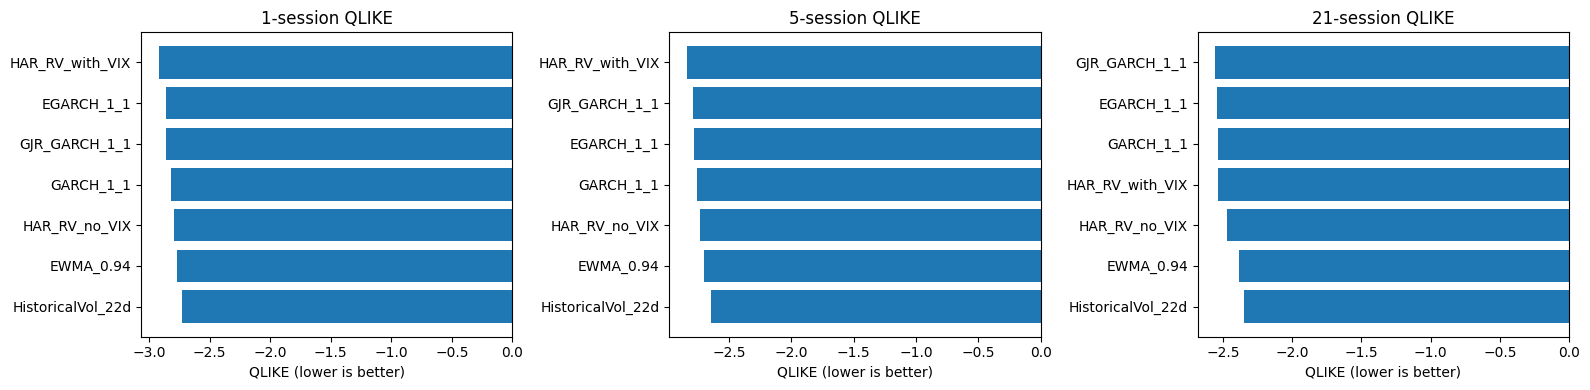

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, h in zip(axes, (1, 5, 21)):
    sub = metrics[(metrics.horizon == h) & metrics.model.isin(econometric)].sort_values('qlike')
    ax.barh(sub.model, sub.qlike)
    ax.set_title(f'{h}-session QLIKE')
    ax.set_xlabel('QLIKE (lower is better)')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Interpretation

HAR + VIX is the strongest QLIKE model at one and five sessions among the traditional econometric / HAR set. At 21 sessions, the QLIKE differences among XGBoost, GARCH-family and HAR models are narrow; the 21-session volatility RMSE ranking differs from the QLIKE ranking. Forecast loss should be specified before choosing a model.

GARCH-family parameter estimates are stored in `outputs/garch_family_parameter_estimates.csv`. The implementation uses a Gaussian QMLE specification; alternative innovation distributions and estimation packages could provide a useful future robustness extension.